# Telugu Hate Speech Detection - Text Modality

Implements the text-modality models in the project plan for **binary** and **5-class** classification:

1. TF-IDF + linear classifier
2. mBERT fine-tuning
3. mBERT embeddings + XGBoost
4. XLM-RoBERTa fine-tuning
5. LaBSE fine-tuning


In [ ]:
!pip -q install -U transformers accelerate scikit-learn xgboost openpyxl seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 82.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 105.6 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, random, re, gc, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

DATASET_PATH = "/content/drive/MyDrive/telugu_dataset/TELUGU DATASET/TE/Excel/TELUGU_METADATA.xlsx"

# All trained models, metrics, predictions and comparison tables will be saved here.
OUTPUT_DIR = "/content/drive/MyDrive/telugu_hate_speech_text_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Transformer settings. Lower BATCH_SIZE if you run out of GPU memory.
MAX_LEN = 128
BATCH_SIZE = 8 if torch.cuda.is_available() else 2
EPOCHS = 3
LEARNING_RATE = 2e-5

Mounted at /content/drive
Device: cuda


## Load and normalize the metadata

In [ ]:
import os
import pandas as pd

print("Dataset path:", DATASET_PATH)
print("File exists:", os.path.isfile(DATASET_PATH))

if os.path.isfile(DATASET_PATH):
    excel_file = pd.ExcelFile(DATASET_PATH)
    print("Available sheet names:", excel_file.sheet_names)

    for sheet in excel_file.sheet_names:
        df = pd.read_excel(DATASET_PATH, sheet_name=sheet, nrows=5)
        print(f"\nSheet: {sheet}")
        print("Columns:", df.columns.tolist())
        display(df.head(2))

Dataset path: /content/drive/MyDrive/telugu_dataset/TELUGU DATASET/TE/Excel/TELUGU_METADATA.xlsx
File exists: True
Available sheet names: ['HATE', 'NON HATE', 'COUNT']

Sheet: HATE
Columns: ['AUDIO FILE NAME', 'CLASS LABLE', 'SHORT LABLE', 'GENDER', 'AGE', 'LANGUAGE', 'TRANSCRIPTION']


,AUDIO FILE NAME,CLASS LABLE,SHORT LABLE,GENDER,AGE,LANGUAGE,TRANSCRIPTION
0,H_TE_001_R_F_001_001,RELIGION,R,F,30,TELUGU,ఎస్సీలుగా పుట్టాలని ఎవరు కోరుకుంటారు
1,H_TE_001_R_F_001_002,RELIGION,R,F,30,TELUGU,ఎవరు మాత్రం SC కులంలో పుట్టాలని కోరుకుంటారు అం...



Sheet: NON HATE
Columns: ['AUDIO FILE NAME', 'CLASS LABLE', 'SHORT LABLE', 'GENDER', 'AGE', 'LANGUAGE', 'TRANSCRIPTION']


,AUDIO FILE NAME,CLASS LABLE,SHORT LABLE,GENDER,AGE,LANGUAGE,TRANSCRIPTION
0,NH_TE_001_N_M_001_001,NON HATE,N,M,25,TELUGU,"భారతదేశమంటేనే ప్రతీఒక్క కులానికి కావచ్చు, ప్రత..."
1,NH_TE_001_N_M_001_002,NON HATE,N,M,25,TELUGU,"ఇవాళ ఈ సమాజం నాకొక గౌరవం నేర్పిచ్చింది, ముస్ల..."



Sheet: COUNT
Columns: ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6']


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6
0,NaN,NaN,HATE,NaN,NaN,NaN,NON HATE
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
def load_sheet(path, sheet_name, task):
    frame = pd.read_excel(path, sheet_name=sheet_name)

    frame = frame[["TRANSCRIPTION", "SHORT LABLE"]].copy()
    frame.columns = ["text", "raw_label"]

    frame["text"] = frame["text"].astype("string").str.strip()
    frame["raw_label"] = frame["raw_label"].astype("string").str.strip().str.upper()

    frame = frame.dropna(subset=["text", "raw_label"])
    frame = frame[frame["text"] != ""]

    if task == "binary":
        # Every row in HATE is hate speech.
        # Every row in NON HATE is non-hate speech.
        raise ValueError(
            "Create the binary dataset by combining HATE and NON HATE sheets."
        )

    mapping = {
        "NH": 0, "N": 0, "NON HATE": 0,
        "C": 1, "G": 2, "R": 3, "P": 4
    }

    frame["label"] = frame["raw_label"].map(mapping)

    invalid = frame["label"].isna().sum()
    if invalid:
        print(f"{sheet_name}: dropping {invalid} rows with unmapped labels.")

    frame = frame.dropna(subset=["label"]).copy()
    frame["label"] = frame["label"].astype(int)

    return frame[["text", "label"]].reset_index(drop=True)


# Read the actual workbook sheets
hate_df = pd.read_excel(DATASET_PATH, sheet_name="HATE")
non_hate_df = pd.read_excel(DATASET_PATH, sheet_name="NON HATE")

# Build binary classification dataset
hate_binary = hate_df[["TRANSCRIPTION"]].copy()
hate_binary.columns = ["text"]
hate_binary["label"] = 1

non_hate_binary = non_hate_df[["TRANSCRIPTION"]].copy()
non_hate_binary.columns = ["text"]
non_hate_binary["label"] = 0

binary_df = pd.concat(
    [hate_binary, non_hate_binary], ignore_index=True
)
binary_df["text"] = binary_df["text"].astype("string").str.strip()
binary_df = binary_df.dropna(subset=["text"])
binary_df = binary_df[binary_df["text"] != ""]
binary_df["label"] = binary_df["label"].astype(int)
binary_df = binary_df.sample(frac=1, random_state=42).reset_index(drop=True)

BINARY_NAMES = {0: "Non-Hate", 1: "Hate"}

# Build five-class dataset
hate_multi = load_sheet(DATASET_PATH, "HATE", "multi")
non_hate_multi = non_hate_df[["TRANSCRIPTION"]].copy()
non_hate_multi.columns = ["text"]
non_hate_multi["label"] = 0

multi_df = pd.concat(
    [hate_multi, non_hate_multi], ignore_index=True
)
multi_df = multi_df.dropna(subset=["text", "label"])
multi_df["label"] = multi_df["label"].astype(int)
multi_df = multi_df.sample(frac=1, random_state=42).reset_index(drop=True)

MULTI_NAMES = {
    0: "NH", 1: "C", 2: "G", 3: "R", 4: "P"
}

print("Binary dataset:", binary_df.shape)
display(binary_df["label"].map(BINARY_NAMES).value_counts().to_frame("count"))

print("\nFive-class dataset:", multi_df.shape)
display(multi_df["label"].map(MULTI_NAMES).value_counts().to_frame("count"))

display(binary_df.head())
display(multi_df.head())

Binary dataset: (601, 2)


,count
label,
Hate,393
Non-Hate,208



Five-class dataset: (601, 2)


,count
label,
NH,208
C,132
G,111
R,82
P,68


,text,label
0,వంద కోట్లు మొత్తం ఆరు కిలోమీటర్లు పోవాలి అంటే ...,1
1,ఒకరెండు తరాల కాలంనుంచి ఈ కులాల కి వ్యతిరేకంగా ...,0
2,ఇక్కడ టీరియన్ చెప్పిన డైలాగ్ మీకు హార్స్ గా అన...,0
3,"తెలుగుదేశంలో మాత్రం అదే జరిగింది, పార్టీ మొత్త...",1
4,అరేయ్వీలు గయ్స్ ఏందీ ర భాయ్ అని నిజంగా కుళ్ళుక...,1


,text,label
0,వంద కోట్లు మొత్తం ఆరు కిలోమీటర్లు పోవాలి అంటే ...,4
1,ఒకరెండు తరాల కాలంనుంచి ఈ కులాల కి వ్యతిరేకంగా ...,0
2,ఇక్కడ టీరియన్ చెప్పిన డైలాగ్ మీకు హార్స్ గా అన...,0
3,"తెలుగుదేశంలో మాత్రం అదే జరిగింది, పార్టీ మొత్త...",3
4,అరేయ్వీలు గయ్స్ ఏందీ ర భాయ్ అని నిజంగా కుళ్ళుక...,2


## Create reproducible stratified splits and shared evaluation helpers

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, f1_score
)

def make_split(frame):
    # Stratify where possible so rare classes are represented in both sets.
    counts = frame["label"].value_counts()
    stratify = frame["label"] if counts.min() >= 2 else None
    train_part, test_part = train_test_split(
        frame, test_size=0.20, random_state=SEED, stratify=stratify
    )
    return (
        train_part.reset_index(drop=True),
        test_part.reset_index(drop=True)
    )

binary_train, binary_test = make_split(binary_df)
multi_train, multi_test = make_split(multi_df)

def evaluate_and_save(y_true, y_pred, class_names, run_name, texts=None):
    labels = list(range(len(class_names)))
    acc = accuracy_score(y_true, y_pred)
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0
    )
    print(f"\n{run_name}: accuracy={acc:.4f}, macro-F1={macro_f1:.4f}")
    print(classification_report(
        y_true, y_pred, labels=labels,
        target_names=[class_names[i] for i in labels],
        zero_division=0
    ))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=[class_names[i] for i in labels],
                yticklabels=[class_names[i] for i in labels])
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(run_name)
    plt.tight_layout()
    plt.show()

    metrics = {
        "model": run_name, "accuracy": float(acc),
        "macro_precision": float(precision), "macro_recall": float(recall),
        "macro_f1": float(macro_f1), "n_test": int(len(y_true))
    }
    with open(os.path.join(OUTPUT_DIR, f"{run_name}_metrics.json"), "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2, ensure_ascii=False)
    pred_df = pd.DataFrame({"true_label": y_true, "predicted_label": y_pred})
    if texts is not None:
        pred_df.insert(0, "text", list(texts))
    pred_df.to_csv(os.path.join(OUTPUT_DIR, f"{run_name}_predictions.csv"), index=False)
    return metrics

all_metrics = []

## TF-IDF model - binary and multiclass

Uses word and character n-grams with a class-weighted linear SVM. Character n-grams are useful for spelling variation and informal social-media text. This is the lightweight baseline and usually trains quickly.


tfidf_binary: accuracy=0.8512, macro-F1=0.8393
              precision    recall  f1-score   support

    Non-Hate       0.76      0.83      0.80        42
        Hate       0.91      0.86      0.88        79

    accuracy                           0.85       121
   macro avg       0.83      0.85      0.84       121
weighted avg       0.86      0.85      0.85       121



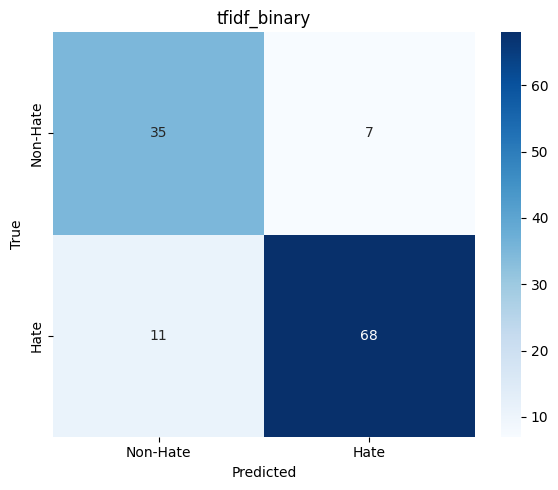


tfidf_multiclass: accuracy=0.8017, macro-F1=0.7758
              precision    recall  f1-score   support

          NH       0.74      0.95      0.83        42
           C       0.85      0.81      0.83        27
           G       0.85      0.77      0.81        22
           R       0.78      0.44      0.56        16
           P       0.92      0.79      0.85        14

    accuracy                           0.80       121
   macro avg       0.83      0.75      0.78       121
weighted avg       0.81      0.80      0.79       121



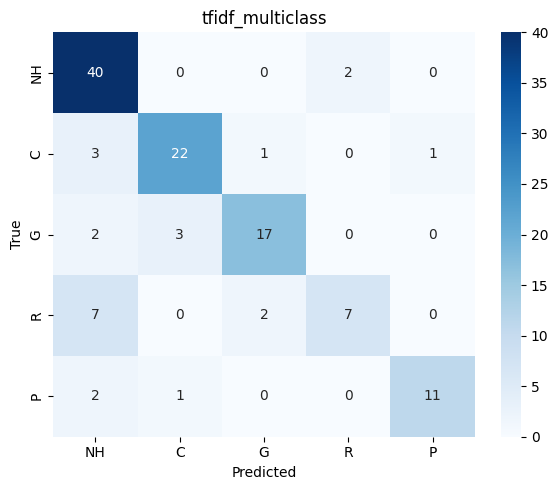

In [ ]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
import joblib

def run_tfidf(train_df, test_df, class_names, run_name):
    model = Pipeline([
        ("features", FeatureUnion([
            ("word", TfidfVectorizer(
                analyzer="word", ngram_range=(1, 2), min_df=1,
                max_features=100000, sublinear_tf=True
            )),
            ("char", TfidfVectorizer(
                analyzer="char", ngram_range=(2, 5), min_df=1,
                max_features=100000, sublinear_tf=True
            ))
        ])),
        ("classifier", LinearSVC(class_weight="balanced", random_state=SEED))
    ])
    model.fit(train_df["text"], train_df["label"])
    preds = model.predict(test_df["text"])
    os.makedirs(os.path.join(OUTPUT_DIR, run_name), exist_ok=True)
    # joblib.dump(model, os.path.join(OUTPUT_DIR, run_name, "pipeline.joblib"))
    metrics = evaluate_and_save(
        test_df["label"].to_numpy(), preds, class_names, run_name, test_df["text"]
    )
    return metrics

all_metrics.append(run_tfidf(binary_train, binary_test, BINARY_NAMES, "tfidf_binary"))
all_metrics.append(run_tfidf(multi_train, multi_test, MULTI_NAMES, "tfidf_multiclass"))

## Transformer utilities

mBERT and XLM-RoBERTa are fine-tuned as sequence classifiers. The implementation uses dynamic padding and the Hugging Face `Trainer` API, following its standard text-classification workflow. Checkpoints and final models are saved to Google Drive.

In [ ]:
from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)

MODEL_CONFIGS = {
    "mbert": "bert-base-multilingual-cased",
    "xlm_roberta": "xlm-roberta-base",
    "labse": "sentence-transformers/LaBSE",
}

class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts = list(texts)
        self.labels = list(map(int, labels))
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.texts[idx]),
            truncation=True,
            max_length=self.max_len
        )
        enc["labels"] = self.labels[idx]
        return enc

def hf_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0)
    }

def run_transformer_classifier(model_key, train_df, test_df, class_names, run_name):
    model_name = MODEL_CONFIGS[model_key]
    num_labels = len(class_names)
    id2label = {int(i): str(class_names[i]) for i in range(num_labels)}
    label2id = {v: k for k, v in id2label.items()}

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=num_labels, id2label=id2label,
        label2id=label2id, ignore_mismatched_sizes=True
    )

    train_ds = TextDataset(train_df["text"], train_df["label"], tokenizer)
    test_ds = TextDataset(test_df["text"], test_df["label"], tokenizer)
    collator = DataCollatorWithPadding(tokenizer=tokenizer)

    train_args = TrainingArguments(
        output_dir=os.path.join(OUTPUT_DIR, run_name + "_trainer"),
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        num_train_epochs=EPOCHS,
        weight_decay=0.01,
        fp16=torch.cuda.is_available(),
        logging_steps=10,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        report_to="none",
        seed=SEED,
        data_seed=SEED,
        dataloader_num_workers=0
    )

    trainer = Trainer(
        model=model, args=train_args,
        train_dataset=train_ds, eval_dataset=test_ds,
        data_collator=collator, compute_metrics=hf_metrics
    )
    trainer.train()
    pred_output = trainer.predict(test_ds)
    preds = np.argmax(pred_output.predictions, axis=1)

    save_path = os.path.join(OUTPUT_DIR, run_name)
    os.makedirs(save_path, exist_ok=True)
    # trainer.save_model(save_path)
    # tokenizer.save_pretrained(save_path)

    metrics = evaluate_and_save(
        pred_output.label_ids, preds, class_names, run_name, test_df["text"]
    )

    del trainer, model, tokenizer, train_ds, test_ds
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return metrics

## mBERT - binary and multiclass

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.520758,0.470327,0.735537,0.719420
2,0.452038,0.553878,0.652893,0.652679
3,0.380792,0.390756,0.818182,0.812535


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


mbert_binary: accuracy=0.8182, macro-F1=0.8125
              precision    recall  f1-score   support

    Non-Hate       0.67      0.93      0.78        42
        Hate       0.95      0.76      0.85        79

    accuracy                           0.82       121
   macro avg       0.81      0.84      0.81       121
weighted avg       0.86      0.82      0.82       121



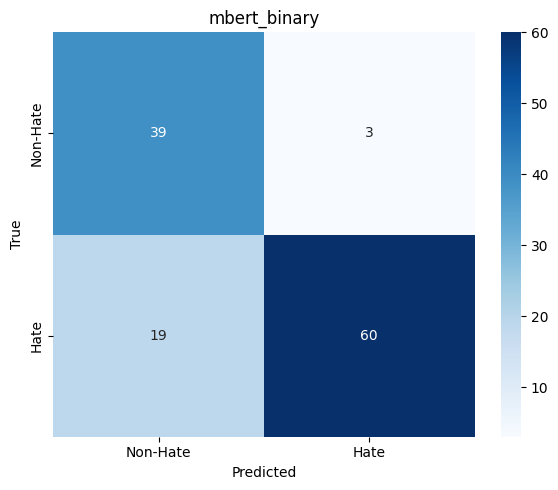

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.234569,1.213239,0.537190,0.282964
2,0.954695,0.986790,0.644628,0.527163
3,0.713522,0.878119,0.652893,0.585461


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


mbert_multiclass: accuracy=0.6529, macro-F1=0.5855
              precision    recall  f1-score   support

          NH       0.63      0.88      0.73        42
           C       0.91      0.74      0.82        27
           G       0.50      0.50      0.50        22
           R       0.60      0.19      0.29        16
           P       0.62      0.57      0.59        14

    accuracy                           0.65       121
   macro avg       0.65      0.58      0.59       121
weighted avg       0.66      0.65      0.63       121



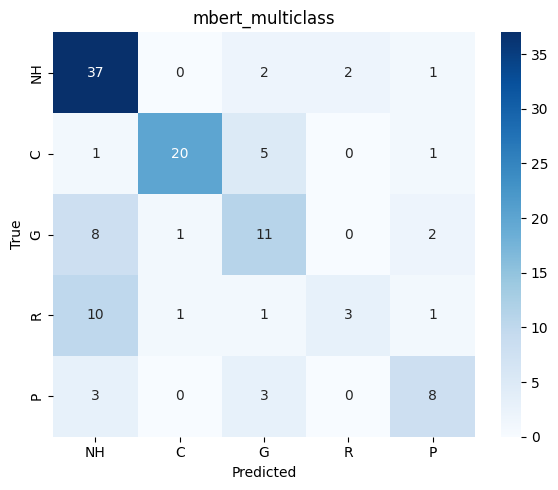

In [ ]:
all_metrics.append(run_transformer_classifier(
    "mbert", binary_train, binary_test, BINARY_NAMES, "mbert_binary"
))
all_metrics.append(run_transformer_classifier(
    "mbert", multi_train, multi_test, MULTI_NAMES, "mbert_multiclass"
))

## mBERT embeddings + XGBoost - binary and multiclass

This model uses the pretrained mBERT encoder to extract a masked mean-pooled text embedding, then trains XGBoost on those vectors. The encoder is not fine-tuned in this experiment. Embeddings are cached to Drive so rerunning the notebook does not need to re-extract them.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



mbert_xgboost_binary: accuracy=0.8017, macro-F1=0.7835
              precision    recall  f1-score   support

    Non-Hate       0.70      0.74      0.72        42
        Hate       0.86      0.84      0.85        79

    accuracy                           0.80       121
   macro avg       0.78      0.79      0.78       121
weighted avg       0.80      0.80      0.80       121



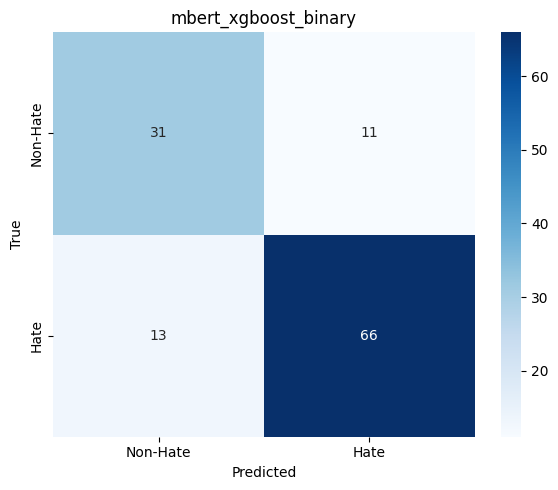

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



mbert_xgboost_multiclass: accuracy=0.6281, macro-F1=0.5472
              precision    recall  f1-score   support

          NH       0.61      0.88      0.72        42
           C       0.75      0.78      0.76        27
           G       0.56      0.41      0.47        22
           R       0.67      0.25      0.36        16
           P       0.50      0.36      0.42        14

    accuracy                           0.63       121
   macro avg       0.62      0.53      0.55       121
weighted avg       0.63      0.63      0.60       121



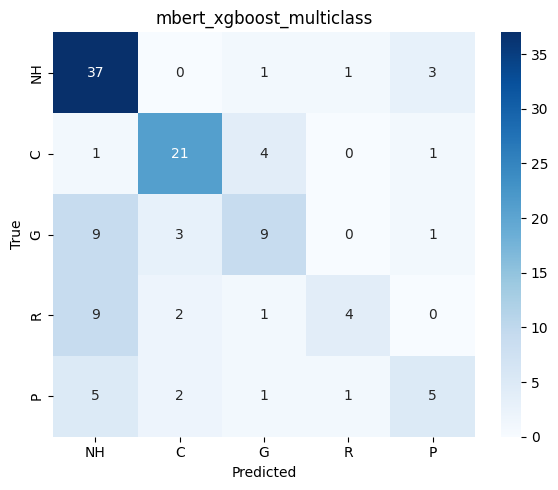

In [ ]:
from transformers import AutoModel
from xgboost import XGBClassifier

def mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    summed = torch.sum(last_hidden_state * mask, dim=1)
    denom = torch.clamp(mask.sum(dim=1), min=1e-9)
    return summed / denom

def extract_mbert_embeddings(texts, cache_path, batch_size=16):
    if os.path.isfile(cache_path):
        cached = np.load(cache_path)
        if len(cached["embeddings"]) == len(texts):
            print("Loading cached embeddings:", cache_path)
            return cached["embeddings"]
    model_name = MODEL_CONFIGS["mbert"]
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    encoder = AutoModel.from_pretrained(model_name).to(DEVICE)
    encoder.eval()
    output = []
    with torch.no_grad():
        for start in range(0, len(texts), batch_size):
            batch = list(texts[start:start + batch_size])
            enc = tokenizer(batch, padding=True, truncation=True, max_length=MAX_LEN,
                            return_tensors="pt")
            enc = {k: v.to(DEVICE) for k, v in enc.items()}
            hidden = encoder(**enc).last_hidden_state
            pooled = mean_pool(hidden, enc["attention_mask"])
            output.append(pooled.cpu().numpy().astype(np.float32))
    embeddings = np.concatenate(output, axis=0)
    np.savez_compressed(cache_path, embeddings=embeddings)
    del encoder, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return embeddings

def run_mbert_xgb(train_df, test_df, class_names, run_name):
    cache_dir = os.path.join(OUTPUT_DIR, "embedding_cache")
    os.makedirs(cache_dir, exist_ok=True)
    # Unique cache names per task and split.
    train_cache = os.path.join(cache_dir, run_name + "_train.npz")
    test_cache = os.path.join(cache_dir, run_name + "_test.npz")
    X_train = extract_mbert_embeddings(train_df["text"].tolist(), train_cache)
    X_test = extract_mbert_embeddings(test_df["text"].tolist(), test_cache)
    y_train = train_df["label"].to_numpy()
    y_test = test_df["label"].to_numpy()
    model = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.04,
        subsample=0.9, colsample_bytree=0.9,
        objective="binary:logistic" if len(class_names) == 2 else "multi:softprob",
        num_class=len(class_names) if len(class_names) > 2 else None,
        eval_metric="logloss" if len(class_names) == 2 else "mlogloss",
        random_state=SEED, n_jobs=2
    )
    model.fit(X_train, y_train)
    preds = model.predict(X_test).astype(int)
    model_dir = os.path.join(OUTPUT_DIR, run_name)
    os.makedirs(model_dir, exist_ok=True)
    # model.save_model(os.path.join(model_dir, "xgboost.json"))
    metrics = evaluate_and_save(y_test, preds, class_names, run_name, test_df["text"])
    return metrics

all_metrics.append(run_mbert_xgb(
    binary_train, binary_test, BINARY_NAMES, "mbert_xgboost_binary"
))
all_metrics.append(run_mbert_xgb(
    multi_train, multi_test, MULTI_NAMES, "mbert_xgboost_multiclass"
))

## XLM-RoBERTa - binary and multiclass

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


xlm_roberta_binary: accuracy=0.8182, macro-F1=0.8114
              precision    recall  f1-score   support

    Non-Hate       0.68      0.90      0.78        42
        Hate       0.94      0.77      0.85        79

    accuracy                           0.82       121
   macro avg       0.81      0.84      0.81       121
weighted avg       0.85      0.82      0.82       121



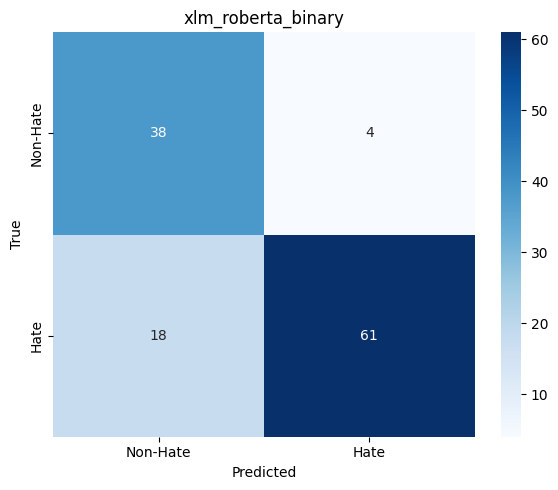

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.331494,1.184542,0.553719,0.287391
2,1.047449,1.051110,0.570248,0.390615
3,0.912469,0.866433,0.702479,0.591579


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.331494,1.184542,0.553719,0.287391
2,1.047449,1.051110,0.570248,0.390615
3,0.912469,0.866433,0.702479,0.591579



xlm_roberta_multiclass: accuracy=0.7025, macro-F1=0.5916
              precision    recall  f1-score   support

          NH       0.67      0.95      0.78        42
           C       0.71      0.89      0.79        27
           G       0.67      0.45      0.54        22
           R       0.00      0.00      0.00        16
           P       0.92      0.79      0.85        14

    accuracy                           0.70       121
   macro avg       0.59      0.62      0.59       121
weighted avg       0.62      0.70      0.64       121



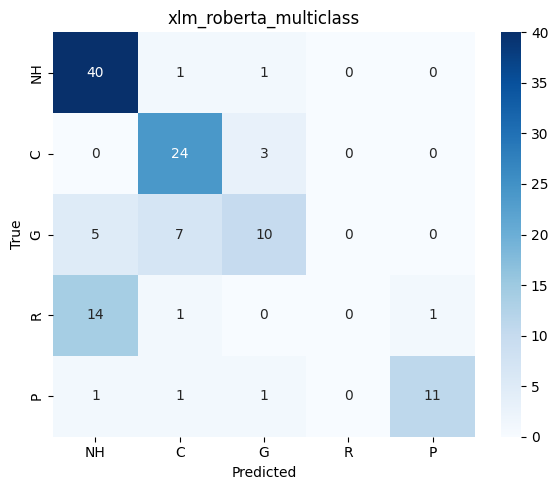

In [ ]:
all_metrics.append(run_transformer_classifier(
    "xlm_roberta", binary_train, binary_test, BINARY_NAMES, "xlm_roberta_binary"
))
all_metrics.append(run_transformer_classifier(
    "xlm_roberta", multi_train, multi_test, MULTI_NAMES, "xlm_roberta_multiclass"
))

In [ ]:
import gc
import torch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("GPU memory cleared")

GPU memory cleared


## LaBSE - binary and multiclass


Google drive space is full. So, I am just training the model without saving. If we need the model in later steps, we will train again (for this LaBSE)

In [ ]:
OUTPUT_DIR = "/content/labse_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

labse_binary | Epoch 1/3 | train loss=0.5318 | train acc=0.7521
labse_binary | Epoch 2/3 | train loss=0.3205 | train acc=0.8583
labse_binary | Epoch 3/3 | train loss=0.1946 | train acc=0.9250

labse_binary: accuracy=0.8926, macro-F1=0.8794
              precision    recall  f1-score   support

    Non-Hate       0.87      0.81      0.84        42
        Hate       0.90      0.94      0.92        79

    accuracy                           0.89       121
   macro avg       0.89      0.87      0.88       121
weighted avg       0.89      0.89      0.89       121



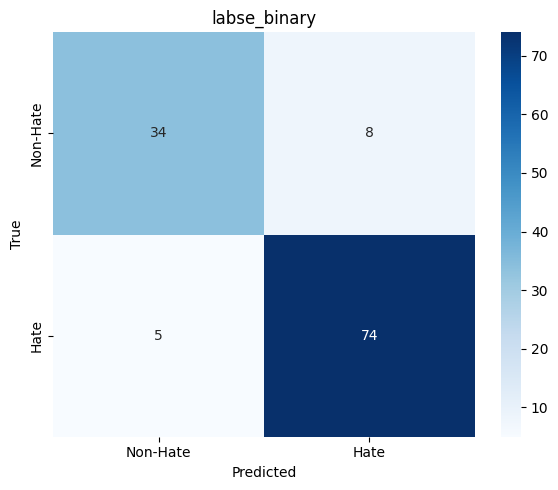

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

labse_multiclass | Epoch 1/3 | train loss=1.3715 | train acc=0.4188
labse_multiclass | Epoch 2/3 | train loss=0.9020 | train acc=0.6750
labse_multiclass | Epoch 3/3 | train loss=0.5723 | train acc=0.8375

labse_multiclass: accuracy=0.8264, macro-F1=0.7929
              precision    recall  f1-score   support

          NH       0.85      0.95      0.90        42
           C       0.91      0.78      0.84        27
           G       0.70      0.86      0.78        22
           R       0.88      0.44      0.58        16
           P       0.81      0.93      0.87        14

    accuracy                           0.83       121
   macro avg       0.83      0.79      0.79       121
weighted avg       0.84      0.83      0.82       121



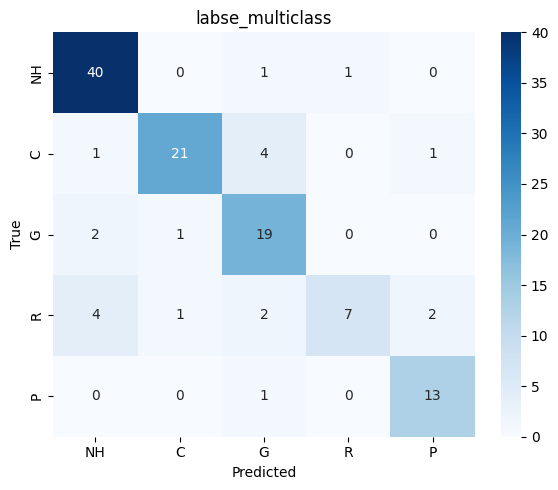

In [ ]:
import os
import gc
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from transformers import AutoModel, AutoTokenizer, DataCollatorWithPadding


import torch.nn as nn
from transformers import AutoModel

class LaBSEClassifier(nn.Module):
    def __init__(self, model_name, num_classes, dropout=0.3):
        super().__init__()
        self.labse = AutoModel.from_pretrained(model_name)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(self.labse.config.hidden_size,num_classes)

    def forward(self,input_ids,attention_mask,token_type_ids=None):
        outputs = self.labse(input_ids=input_ids,attention_mask=attention_mask,token_type_ids=token_type_ids)
        pooled = outputs.pooler_output
        return self.out(self.drop(pooled))


def make_labse_loaders(train_df, test_df, model_name, batch_size=BATCH_SIZE):
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    train_ds = TextDataset(
        train_df["text"], train_df["label"], tokenizer
    )
    test_ds = TextDataset(
        test_df["text"], test_df["label"], tokenizer
    )

    collator = DataCollatorWithPadding(
        tokenizer=tokenizer,
        return_tensors="pt"
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=collator
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collator
    )

    return tokenizer, train_loader, test_loader


def run_labse(train_df, test_df, class_names, run_name):
    model_name = MODEL_CONFIGS["labse"]

    tokenizer, train_loader, test_loader = make_labse_loaders(
        train_df, test_df, model_name
    )

    model = LaBSEClassifier(
        model_name, len(class_names)
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-5,
        weight_decay=0.01
    )

    loss_fn = nn.CrossEntropyLoss()

    for epoch in range(EPOCHS):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for batch in train_loader:
            labels = batch.pop("labels").to(DEVICE)
            batch = {k: v.to(DEVICE) for k, v in batch.items()}

            optimizer.zero_grad(set_to_none=True)

            logits = model(**batch)
            loss = loss_fn(logits, labels)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        print(
            f"{run_name} | Epoch {epoch+1}/{EPOCHS} "
            f"| train loss={running_loss/max(total,1):.4f} "
            f"| train acc={correct/max(total,1):.4f}"
        )

    # Evaluation
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for batch in test_loader:
            labels = batch.pop("labels")
            batch = {k: v.to(DEVICE) for k, v in batch.items()}

            logits = model(**batch)

            y_true.extend(labels.numpy().tolist())
            y_pred.extend(
                logits.argmax(dim=1).cpu().numpy().tolist()
            )

    metrics = evaluate_and_save(
        np.asarray(y_true),
        np.asarray(y_pred),
        class_names,
        run_name,
        test_df["text"]
    )

    # Release memory
    del model, tokenizer, train_loader, test_loader
    del optimizer, loss_fn
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return metrics


# Train both tasks, neither trained model is saved.
all_metrics.append(run_labse(binary_train,binary_test,BINARY_NAMES,"labse_binary"))
all_metrics.append(run_labse(multi_train,multi_test,MULTI_NAMES,"labse_multiclass"))

## Compare all text models

This creates one table sorted by macro-F1. Macro-F1 is particularly important when the classes are imbalanced.

In [ ]:
import os
import pandas as pd
from IPython.display import display

# Check collected results
print("Number of model results:", len(all_metrics))

comparison = pd.DataFrame(all_metrics)

if "macro_f1" in comparison.columns:
    comparison = comparison.sort_values(
        "macro_f1", ascending=False
    ).reset_index(drop=True)

display(comparison)

# Save locally in Colab, not Google Drive
OUTPUT_DIR = "/content/labse_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

comparison_path = os.path.join(
    OUTPUT_DIR, "text_model_comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

print("Saved comparison:", comparison_path)

Number of model results: 14


,model,accuracy,macro_precision,macro_recall,macro_f1,n_test
0,labse_binary,0.892562,0.887117,0.873116,0.879380,121
1,tfidf_binary,0.851240,0.833768,0.847046,0.839286,121
2,tfidf_binary,0.851240,0.833768,0.847046,0.839286,121
3,mbert_binary,0.818182,0.812397,0.844033,0.812535,121
4,xlm_roberta_binary,0.818182,0.808516,0.838457,0.811366,121
5,labse_multiclass,0.826446,0.831062,0.791973,0.792877,121
6,mbert_xgboost_binary,0.801653,0.780844,0.786769,0.783542,121
7,tfidf_multiclass,0.801653,0.826268,0.752627,0.775840,121
8,tfidf_multiclass,0.801653,0.826268,0.752627,0.775840,121
9,mbert_binary,0.776860,0.783662,0.812387,0.772888,121


Saved comparison: /content/labse_results/text_model_comparison.csv
